[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juansensio/blog/blob/master/096_ml_unsupervised/096_ml_unsupervised.ipynb)

# ML - Aprendizaje No Supervisado

> **Versión modificada:** incorpora los ejercicios solicitados de generación aleatoria y K-Means en 2D y 3D, incluyendo número aleatorio de centroides (1–20), separación visual, dispersión y cantidad de puntos aleatorias, conteo por cluster, cinco puntos más cercanos y gráficas del proceso de entrenamiento.

Si bien todos los ejemplos de *Machine Learning* que hemos visto hasta ahora en esta serie se han basado en aprendizaje supervisado (nuestros datos van acompañados de las etiquetas correspondientes, ejemplos de la tarea que queremos llevar a cabo) la mayoría de los datos no están etiquetados. Antes esta problemática tenemos dos alternativas: etiquetar datos manualmente (lo cual require de tiempo, esfuerzo y dinero en el caso de querer desarrollar sistemas reales) o bien usar técnicas de aprendizaje no supervisado, o *Unsupervised Learning* en inglés.

## Clustering

De entre las diferentes técnicas de aprendizaje no supervisado, el *Clustering* es una de las más usadas. Este técnica consiste en identificar aquellas muestras similares del conjunto de datos y asignarlas a un *cluster*, o grupo. Esto permite aplicaciones tales como: segmentación de clientes, análisis de datos, reducción de la dimensionalidad, detección de anomalías, aprendizaje semi-supervisado, motores de búsqueda e incluso la semgentación de imágenes.

### K-Means

El algoritmo de *K-Means* es uno de los más usados a la hora de aplicar *Clustering*, ya que es un método rápido y eficiente. Vamos a generar un conjunto de datos sintético para aprender a usar esta técnica.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist

# ============================================================
# PUNTO 1 - GENERACIÓN ALEATORIA DE CLUSTERS EN 2D
# ============================================================
# SEMILLA = None  -> cada ejecución genera un dataset diferente.
# Para repetir exactamente un experimento, use por ejemplo SEMILLA = 42.
SEMILLA = None
rng = np.random.default_rng(SEMILLA)

# Cantidad aleatoria de centroides entre 1 y 20
n_centers = int(rng.integers(1, 21))

# Parámetros de separación. La separación mínima es suficientemente grande
# respecto a la dispersión máxima para facilitar la verificación visual.
LIMITE = 50.0
DISTANCIA_MINIMA = 8.0
STD_MIN, STD_MAX = 0.55, 1.80
PUNTOS_MIN, PUNTOS_MAX = 70, 220


def generar_centroides_separados(n_centers, dimensiones, limite, distancia_minima, rng):
    """Genera centroides aleatorios manteniendo una distancia mínima entre ellos."""
    centros = []
    intentos = 0
    max_intentos = 100000

    while len(centros) < n_centers and intentos < max_intentos:
        candidato = rng.uniform(-limite, limite, size=dimensiones)
        if not centros or all(np.linalg.norm(candidato - c) >= distancia_minima for c in centros):
            centros.append(candidato)
        intentos += 1

    if len(centros) != n_centers:
        raise RuntimeError("No fue posible ubicar todos los centroides con la separación solicitada.")
    return np.asarray(centros)


# 1) Posiciones aleatorias de los centroides
blob_centers = generar_centroides_separados(
    n_centers=n_centers,
    dimensiones=2,
    limite=LIMITE,
    distancia_minima=DISTANCIA_MINIMA,
    rng=rng
)

# 2) Distancia/dispersión aleatoria de los puntos respecto a cada centroide
blob_std = rng.uniform(STD_MIN, STD_MAX, size=n_centers)

# 3) Número aleatorio de puntos por centroide
puntos_por_centroide_generado = rng.integers(PUNTOS_MIN, PUNTOS_MAX + 1, size=n_centers)

# Generación manual para que cada cluster tenga su propio número de puntos
X_partes = []
y_partes = []
for i, (centro, sigma, n_puntos) in enumerate(
    zip(blob_centers, blob_std, puntos_por_centroide_generado)
):
    puntos = rng.normal(loc=centro, scale=sigma, size=(int(n_puntos), 2))
    X_partes.append(puntos)
    y_partes.append(np.full(int(n_puntos), i, dtype=int))

X = np.vstack(X_partes)
y = np.concatenate(y_partes)

# Mezclar las muestras para evitar que queden ordenadas por cluster
orden = rng.permutation(len(X))
X, y = X[orden], y[orden]

print(f"Número de centroides generados: {n_centers}")
print(f"Número total de puntos: {len(X)}")
print("\nCentroides generadores (2D):")
print(np.round(blob_centers, 3))
print("\nDispersión (sigma) por centroide:")
print(np.round(blob_std, 3))
print("\nNúmero de puntos generados por centroide:")
print(puntos_por_centroide_generado)


Número de centroides generados: 5
Número total de puntos: 725

Centroides generadores (2D):
[[-30.903  44.501]
 [ 28.662  34.001]
 [ 22.73  -39.591]
 [ 18.221 -26.229]
 [-49.581  33.667]]

Dispersión (sigma) por centroide:
[1.555 0.695 0.862 1.649 0.826]

Número de puntos generados por centroide:
[105  88 171 194 167]


In [ ]:
import matplotlib.pyplot as plt

def plot_clusters(X, y=None):
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$", fontsize=14)
    plt.ylabel("$x_2$", fontsize=14, rotation=0)

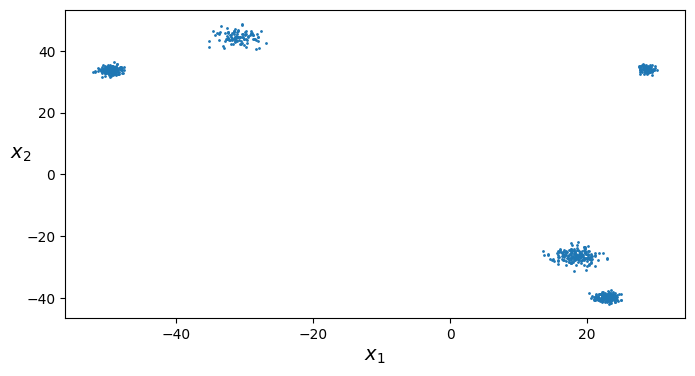

In [ ]:
plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.show()

En *Scikit-Learn* puedes usar el objeto [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), indicando el número de clusters deseado.  

In [ ]:
from sklearn.cluster import KMeans
k = len(blob_centers)
#k = 5
kmeans = KMeans(n_clusters=k, random_state=42)
y_pred = kmeans.fit_predict(X)
y_pred         #devolver las etiques de cada grupo y

array([1, 4, 0, 3, 4, 4, 4, 3, 1, 1, 0, 2, 3, 3, 3, 4, 3, 2, 1, 3, 1, 1,
       3, 2, 2, 2, 1, 0, 2, 4, 2, 0, 2, 1, 3, 3, 3, 4, 4, 2, 4, 1, 4, 2,
       0, 2, 3, 1, 3, 1, 1, 3, 3, 3, 4, 3, 1, 3, 3, 1, 1, 3, 3, 2, 3, 0,
       2, 1, 1, 2, 3, 1, 4, 1, 2, 1, 3, 2, 4, 3, 4, 3, 2, 1, 2, 4, 3, 2,
       3, 3, 1, 4, 1, 4, 4, 4, 1, 2, 1, 2, 3, 1, 1, 3, 2, 4, 0, 0, 3, 3,
       3, 4, 1, 2, 3, 0, 3, 2, 1, 0, 1, 3, 0, 1, 2, 1, 1, 0, 0, 3, 3, 4,
       2, 3, 1, 0, 1, 1, 3, 1, 3, 2, 4, 4, 1, 2, 3, 2, 3, 1, 1, 2, 3, 3,
       3, 2, 1, 3, 1, 1, 2, 1, 2, 1, 2, 4, 3, 4, 1, 0, 4, 4, 3, 3, 3, 3,
       4, 4, 3, 2, 1, 3, 3, 4, 2, 2, 4, 3, 3, 2, 2, 4, 3, 4, 3, 2, 2, 1,
       1, 2, 3, 1, 0, 1, 4, 2, 3, 2, 2, 3, 2, 2, 3, 0, 1, 4, 2, 0, 3, 4,
       3, 1, 1, 3, 3, 3, 2, 0, 3, 2, 3, 2, 1, 1, 3, 2, 4, 4, 1, 0, 1, 0,
       1, 2, 2, 3, 2, 3, 3, 1, 3, 3, 2, 1, 3, 1, 4, 2, 1, 3, 2, 1, 2, 0,
       2, 2, 3, 3, 2, 4, 4, 0, 4, 2, 0, 3, 4, 1, 3, 2, 3, 0, 1, 2, 2, 0,
       1, 3, 2, 2, 3, 1, 0, 0, 0, 2, 3, 1, 4, 2, 0,

In [ ]:
kmeans.cluster_centers_  # centro de los clusters

array([[ 28.69340642,  34.11367226],
       [ 22.8512944 , -39.67129585],
       [-49.5786345 ,  33.76057831],
       [ 18.36974052, -26.28313524],
       [-31.06259646,  44.44873903]])

In [ ]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])  #Predecir nuevas ubicaciones
kmeans.predict(X_new)

array([3, 3, 3, 3], dtype=int32)

In [ ]:
def plot_data(X):
    plt.plot(X[:, 0], X[:, 1], 'k.', markersize=2)

def plot_centroids(centroids, weights=None, circle_color='w', cross_color='k'):
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=10, linewidths=8,
                color=circle_color, zorder=10, alpha=0.9)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=2, linewidths=10,
                color=cross_color, zorder=11, alpha=1)

def plot_decision_boundaries(clusterer, X, resolution=1000, show_centroids=True,
                             show_xlabels=True, show_ylabels=True):
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(np.linspace(mins[0], maxs[0], resolution),
                         np.linspace(mins[1], maxs[1], resolution))
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                cmap="Pastel2")
    plt.contour(Z, extent=(mins[0], maxs[0], mins[1], maxs[1]),
                linewidths=1, colors='k')
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$", fontsize=14)
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", fontsize=14, rotation=0)
    else:
        plt.tick_params(labelleft=False)

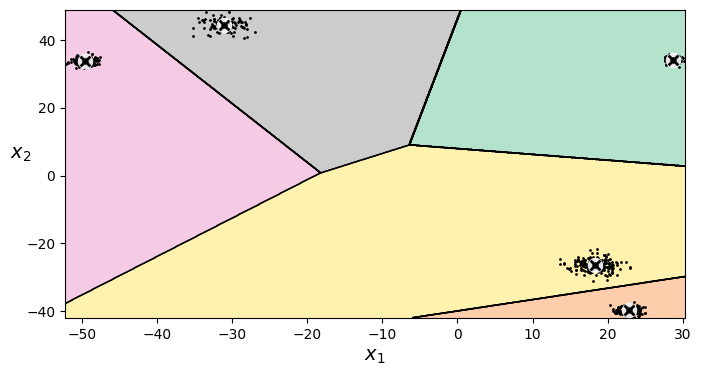

In [ ]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

## Actividad solicitada — Punto 1: K-Means con datos 2D

En esta sección se completa el ejercicio solicitado: se aplica **K-Means** al dataset aleatorio generado anteriormente, se informa el número de puntos asignados a cada centroide, se localizan los **5 puntos más cercanos** a cada centroide y se visualiza tanto el resultado final como la evolución del entrenamiento.

In [ ]:
# ============================================================
# PUNTO 1 - ENTRENAMIENTO FINAL DE K-MEANS EN 2D
# ============================================================

k = n_centers
kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
y_pred = kmeans.fit_predict(X)
centroides_finales = kmeans.cluster_centers_

# Cantidad de puntos asignados a cada cluster aprendido
conteos_cluster = np.bincount(y_pred, minlength=k)

print("Resultado final de K-Means (2D)")
print("=" * 45)
print(f"Número de clusters: {k}")
print(f"Inercia final: {kmeans.inertia_:.4f}")
print(f"Iteraciones realizadas: {kmeans.n_iter_}")
print("\nPuntos asignados a cada centroide aprendido:")
for i, cantidad in enumerate(conteos_cluster):
    print(f"  Cluster {i:2d}: {cantidad:4d} puntos | centroide = {np.round(centroides_finales[i], 3)}")


Resultado final de K-Means (2D)
Número de clusters: 5
Inercia final: 2194.5363
Iteraciones realizadas: 2

Puntos asignados a cada centroide aprendido:
  Cluster  0:   88 puntos | centroide = [28.693 34.114]
  Cluster  1:  171 puntos | centroide = [ 22.851 -39.671]
  Cluster  2:  167 puntos | centroide = [-49.579  33.761]
  Cluster  3:  194 puntos | centroide = [ 18.37  -26.283]
  Cluster  4:  105 puntos | centroide = [-31.063  44.449]


In [ ]:
# ============================================================
# 5 PUNTOS MÁS CERCANOS A CADA CENTROIDE APRENDIDO
# ============================================================

distancias = cdist(X, centroides_finales)
indices_5_cercanos = {}

for i in range(k):
    indices_cluster = np.where(y_pred == i)[0]
    dist_cluster = distancias[indices_cluster, i]
    orden_local = np.argsort(dist_cluster)[:min(5, len(indices_cluster))]
    indices_5_cercanos[i] = indices_cluster[orden_local]

    print(f"\nCluster {i} - 5 puntos más cercanos al centroide {np.round(centroides_finales[i], 3)}")
    for puesto, idx in enumerate(indices_5_cercanos[i], start=1):
        print(
            f"  {puesto}. índice={idx:4d} | punto={np.round(X[idx], 3)} "
            f"| distancia={distancias[idx, i]:.5f}"
        )



Cluster 0 - 5 puntos más cercanos al centroide [28.693 34.114]
  1. índice= 637 | punto=[28.758 34.021] | distancia=0.11327
  2. índice= 387 | punto=[28.77  33.999] | distancia=0.13842
  3. índice= 271 | punto=[28.443 34.038] | distancia=0.26203
  4. índice= 202 | punto=[28.961 34.174] | distancia=0.27436
  5. índice= 368 | punto=[28.853 34.371] | distancia=0.30279

Cluster 1 - 5 puntos más cercanos al centroide [ 22.851 -39.671]
  1. índice= 520 | punto=[ 22.734 -39.642] | distancia=0.12070
  2. índice= 556 | punto=[ 22.739 -39.76 ] | distancia=0.14246
  3. índice=  83 | punto=[ 22.78  -39.541] | distancia=0.14831
  4. índice= 255 | punto=[ 22.64  -39.617] | distancia=0.21848
  5. índice= 362 | punto=[ 22.908 -39.882] | distancia=0.21862

Cluster 2 - 5 puntos más cercanos al centroide [-49.579  33.761]
  1. índice= 604 | punto=[-49.672  33.694] | distancia=0.11457
  2. índice= 313 | punto=[-49.661  33.669] | distancia=0.12251
  3. índice= 265 | punto=[-49.487  33.934] | distancia=0.1

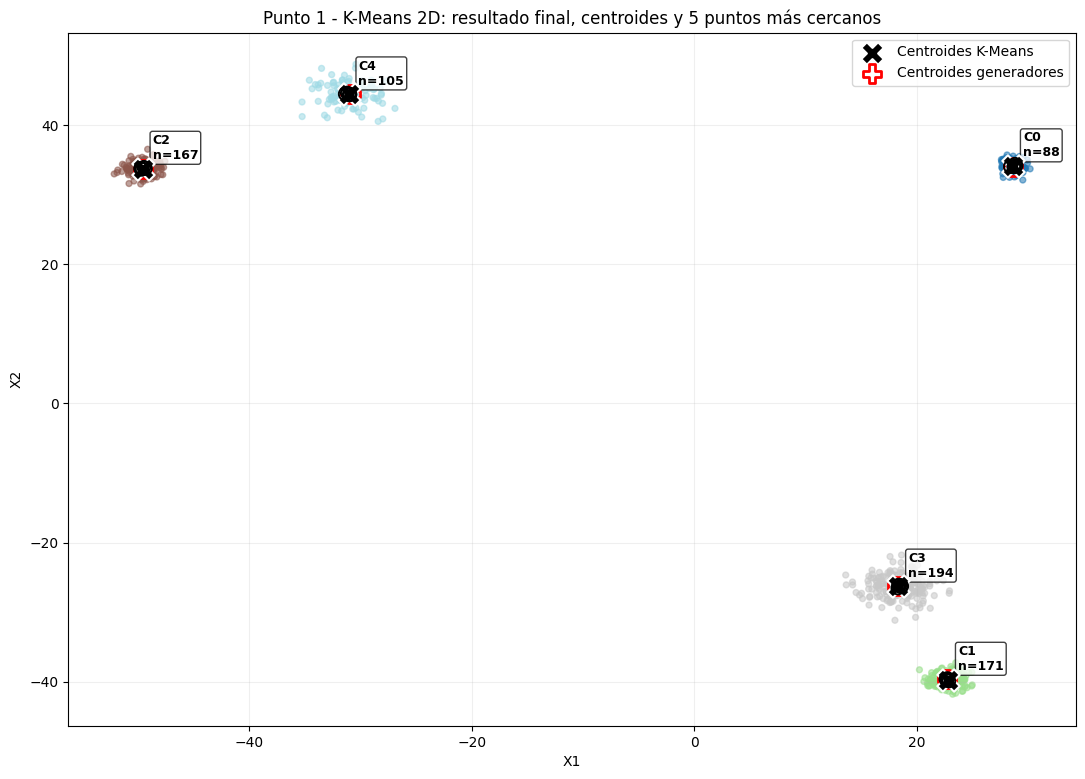

In [ ]:
# ============================================================
# GRÁFICA FINAL 2D
# - puntos coloreados por cluster
# - centroides finales
# - cantidad de puntos por cluster
# - 5 puntos más cercanos resaltados
# ============================================================

plt.figure(figsize=(13, 9))
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="tab20", s=18, alpha=0.55)

# Centroides aprendidos
plt.scatter(
    centroides_finales[:, 0], centroides_finales[:, 1],
    marker="X", s=260, c="black", edgecolors="white", linewidths=1.5,
    label="Centroides K-Means", zorder=6
)

# Centroides originales, útiles para verificación visual
plt.scatter(
    blob_centers[:, 0], blob_centers[:, 1],
    marker="P", s=170, facecolors="none", edgecolors="red", linewidths=2,
    label="Centroides generadores", zorder=5
)

# Cinco puntos más cercanos de cada cluster
for i, indices in indices_5_cercanos.items():
    pts = X[indices]
    plt.scatter(
        pts[:, 0], pts[:, 1],
        s=85, facecolors="none", edgecolors="black", linewidths=1.4, zorder=7
    )
    # Mostrar cantidad de puntos junto al centroide
    cx, cy = centroides_finales[i]
    plt.annotate(
        f"C{i}\nn={conteos_cluster[i]}",
        (cx, cy), xytext=(7, 7), textcoords="offset points",
        fontsize=9, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.75)
    )

plt.title("Punto 1 - K-Means 2D: resultado final, centroides y 5 puntos más cercanos")
plt.xlabel("X1")
plt.ylabel("X2")
plt.grid(alpha=0.2)
plt.legend(loc="best")
plt.show()


### Visualización del proceso de entrenamiento en 2D

Para observar el proceso, se utiliza la misma inicialización aleatoria en todas las ejecuciones parciales y se incrementa `max_iter`. De esta forma se puede comparar la posición de los centroides tras 1, 2, 3, 5 iteraciones y con el modelo convergido.

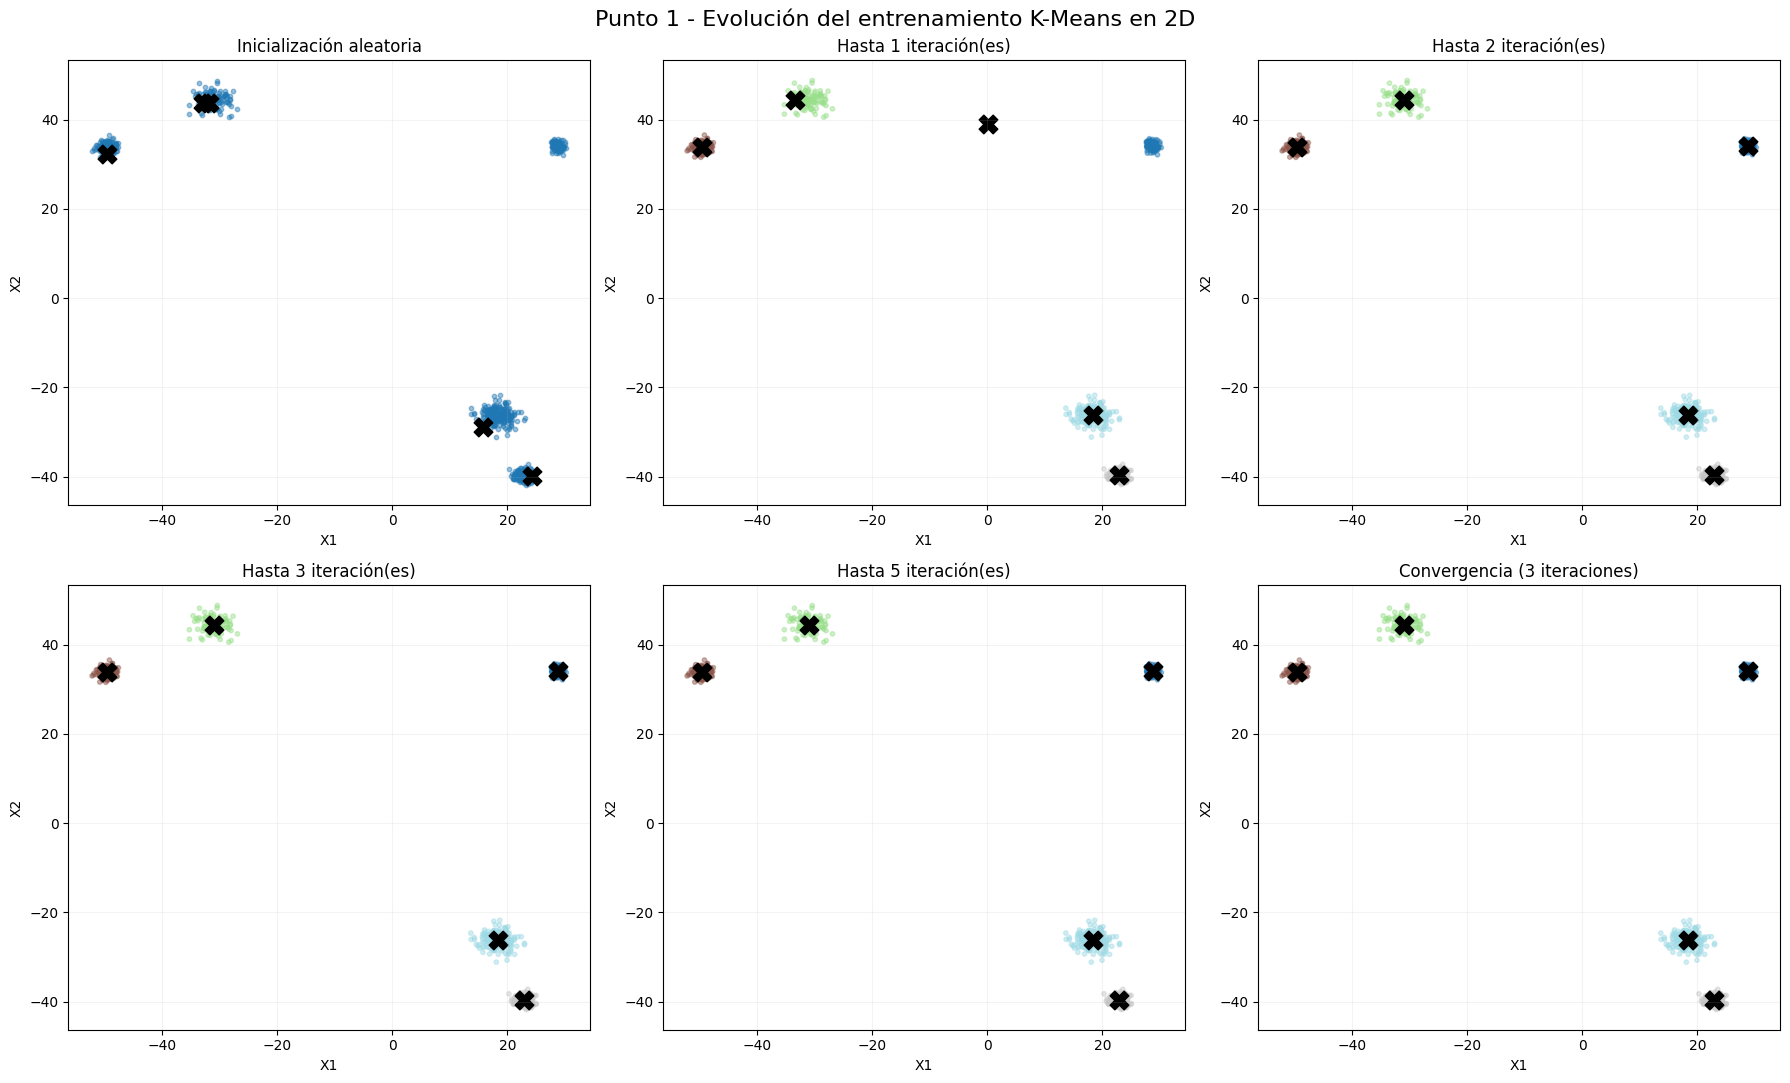

In [ ]:
# ============================================================
# PROCESO DE K-MEANS EN 2D
# ============================================================

# Inicialización común para poder comparar iteraciones sucesivas
rng_proceso = np.random.default_rng(123)
indices_init = rng_proceso.choice(len(X), size=k, replace=False)
centros_iniciales = X[indices_init].copy()

iteraciones_mostradas = [1, 2, 3, 5]
modelos_proceso = []

for max_iter in iteraciones_mostradas:
    modelo = KMeans(
        n_clusters=k,
        init=centros_iniciales,
        n_init=1,
        max_iter=max_iter,
        algorithm="lloyd",
        random_state=123
    )
    modelo.fit(X)
    modelos_proceso.append((max_iter, modelo))

modelo_convergido = KMeans(
    n_clusters=k,
    init=centros_iniciales,
    n_init=1,
    max_iter=300,
    algorithm="lloyd",
    random_state=123
).fit(X)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()

# Panel 0: dataset + centroides iniciales
axes[0].scatter(X[:, 0], X[:, 1], s=10, alpha=0.45)
axes[0].scatter(centros_iniciales[:, 0], centros_iniciales[:, 1], marker="X", s=180, c="black")
axes[0].set_title("Inicialización aleatoria")

# Paneles 1-4: iteraciones parciales
for ax, (max_iter, modelo) in zip(axes[1:5], modelos_proceso):
    etiquetas = modelo.labels_
    ax.scatter(X[:, 0], X[:, 1], c=etiquetas, cmap="tab20", s=10, alpha=0.45)
    ax.scatter(
        modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1],
        marker="X", s=180, c="black"
    )
    ax.set_title(f"Hasta {max_iter} iteración(es)")

# Panel 5: convergencia
axes[5].scatter(X[:, 0], X[:, 1], c=modelo_convergido.labels_, cmap="tab20", s=10, alpha=0.45)
axes[5].scatter(
    modelo_convergido.cluster_centers_[:, 0], modelo_convergido.cluster_centers_[:, 1],
    marker="X", s=180, c="black"
)
axes[5].set_title(f"Convergencia ({modelo_convergido.n_iter_} iteraciones)")

for ax in axes:
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(alpha=0.15)

plt.suptitle("Punto 1 - Evolución del entrenamiento K-Means en 2D", fontsize=16)
plt.tight_layout()
plt.show()


## Actividad solicitada — Punto 2: K-Means con datos 3D

Se repite el procedimiento anterior en tres dimensiones: número aleatorio de centroides, posiciones aleatorias, dispersión aleatoria, cantidad aleatoria de puntos por centroide, entrenamiento con K-Means, conteo de puntos, identificación de los cinco puntos más cercanos y visualización de la evolución del entrenamiento.

In [ ]:
# ============================================================
# PUNTO 2 - GENERACIÓN ALEATORIA DE CLUSTERS EN 3D
# ============================================================

SEMILLA_3D = None
rng3 = np.random.default_rng(SEMILLA_3D)

n_centers_3d = int(rng3.integers(1, 21))
LIMITE_3D = 50.0
DISTANCIA_MINIMA_3D = 10.0
STD_MIN_3D, STD_MAX_3D = 0.60, 2.00
PUNTOS_MIN_3D, PUNTOS_MAX_3D = 70, 220

centros_3d_generados = generar_centroides_separados(
    n_centers=n_centers_3d,
    dimensiones=3,
    limite=LIMITE_3D,
    distancia_minima=DISTANCIA_MINIMA_3D,
    rng=rng3
)

std_3d = rng3.uniform(STD_MIN_3D, STD_MAX_3D, size=n_centers_3d)
puntos_por_centroide_3d = rng3.integers(
    PUNTOS_MIN_3D, PUNTOS_MAX_3D + 1, size=n_centers_3d
)

X3_partes = []
y3_partes = []
for i, (centro, sigma, n_puntos) in enumerate(
    zip(centros_3d_generados, std_3d, puntos_por_centroide_3d)
):
    puntos = rng3.normal(loc=centro, scale=sigma, size=(int(n_puntos), 3))
    X3_partes.append(puntos)
    y3_partes.append(np.full(int(n_puntos), i, dtype=int))

X3 = np.vstack(X3_partes)
y3 = np.concatenate(y3_partes)
orden3 = rng3.permutation(len(X3))
X3, y3 = X3[orden3], y3[orden3]

print(f"Número de centroides generados en 3D: {n_centers_3d}")
print(f"Número total de puntos 3D: {len(X3)}")
print("\nCentroides generadores 3D:")
print(np.round(centros_3d_generados, 3))
print("\nDispersión por centroide 3D:")
print(np.round(std_3d, 3))
print("\nNúmero de puntos por centroide 3D:")
print(puntos_por_centroide_3d)


Número de centroides generados en 3D: 14
Número total de puntos 3D: 2151

Centroides generadores 3D:
[[  8.037   2.349  17.065]
 [-25.259 -28.055   8.516]
 [-45.56   -3.984 -20.84 ]
 [-39.096 -32.639  -3.222]
 [-27.052  10.549  11.758]
 [-18.222  19.666  39.829]
 [-13.708  -4.92   -3.143]
 [-13.     38.43    7.348]
 [ 14.756  26.076  24.249]
 [-28.3    39.527 -46.92 ]
 [ 13.997  17.813 -31.538]
 [-19.843   0.368  11.802]
 [-19.848 -32.955 -23.302]
 [-15.176 -12.625 -15.613]]

Dispersión por centroide 3D:
[1.126 1.719 0.933 1.096 0.812 1.618 1.666 0.894 1.512 1.017 1.038 1.193
 1.165 1.633]

Número de puntos por centroide 3D:
[210 141 200 103 187 208  78 164 165 119 172 182 123  99]


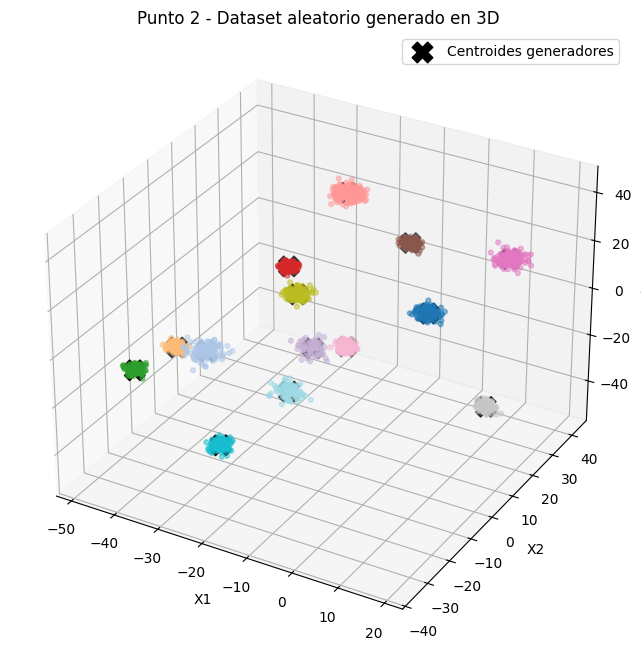

In [ ]:
# Dataset generado en 3D
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], c=y3, cmap="tab20", s=12, alpha=0.5)
ax.scatter(
    centros_3d_generados[:, 0], centros_3d_generados[:, 1], centros_3d_generados[:, 2],
    marker="X", s=220, c="black", label="Centroides generadores"
)
ax.set_title("Punto 2 - Dataset aleatorio generado en 3D")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X3")
ax.legend()
plt.show()


In [ ]:
# ============================================================
# ENTRENAMIENTO FINAL DE K-MEANS EN 3D
# ============================================================

k3 = n_centers_3d
kmeans3 = KMeans(n_clusters=k3, init="k-means++", n_init=10, random_state=42)
y3_pred = kmeans3.fit_predict(X3)
centroides_3d_finales = kmeans3.cluster_centers_
conteos_3d = np.bincount(y3_pred, minlength=k3)

# Distancias y 5 puntos más cercanos
D3 = cdist(X3, centroides_3d_finales)
indices_5_cercanos_3d = {}

print("Resultado final de K-Means (3D)")
print("=" * 45)
print(f"Número de clusters: {k3}")
print(f"Inercia final: {kmeans3.inertia_:.4f}")
print(f"Iteraciones realizadas: {kmeans3.n_iter_}")

for i in range(k3):
    indices_cluster = np.where(y3_pred == i)[0]
    dist_cluster = D3[indices_cluster, i]
    orden_local = np.argsort(dist_cluster)[:min(5, len(indices_cluster))]
    elegidos = indices_cluster[orden_local]
    indices_5_cercanos_3d[i] = elegidos

    print(f"\nCluster {i}: {conteos_3d[i]} puntos | centroide={np.round(centroides_3d_finales[i], 3)}")
    for puesto, idx in enumerate(elegidos, start=1):
        print(
            f"  {puesto}. índice={idx:4d} | punto={np.round(X3[idx], 3)} "
            f"| distancia={D3[idx, i]:.5f}"
        )


Resultado final de K-Means (3D)
Número de clusters: 14
Inercia final: 10019.0510
Iteraciones realizadas: 2

Cluster 0: 210 puntos | centroide=[ 7.879  2.498 17.13 ]
  1. índice=1310 | punto=[ 7.883  2.584 17.047] | distancia=0.11976
  2. índice= 612 | punto=[ 8.094  2.374 17.282] | distancia=0.29075
  3. índice=1999 | punto=[ 7.928  2.119 17.051] | distancia=0.39038
  4. índice= 916 | punto=[ 7.485  2.506 17.043] | distancia=0.40332
  5. índice=1578 | punto=[ 7.609  2.452 16.772] | distancia=0.45113

Cluster 1: 200 puntos | centroide=[-45.547  -3.95  -20.859]
  1. índice= 189 | punto=[-45.452  -3.975 -20.86 ] | distancia=0.09877
  2. índice=1748 | punto=[-45.526  -3.895 -21.091] | distancia=0.23941
  3. índice= 318 | punto=[-45.524  -3.713 -20.689] | distancia=0.29258
  4. índice= 484 | punto=[-45.689  -3.628 -20.763] | distancia=0.36505
  5. índice=1914 | punto=[-45.388  -3.611 -20.845] | distancia=0.37484

Cluster 2: 172 puntos | centroide=[ 14.093  17.932 -31.456]
  1. índice=1720 |

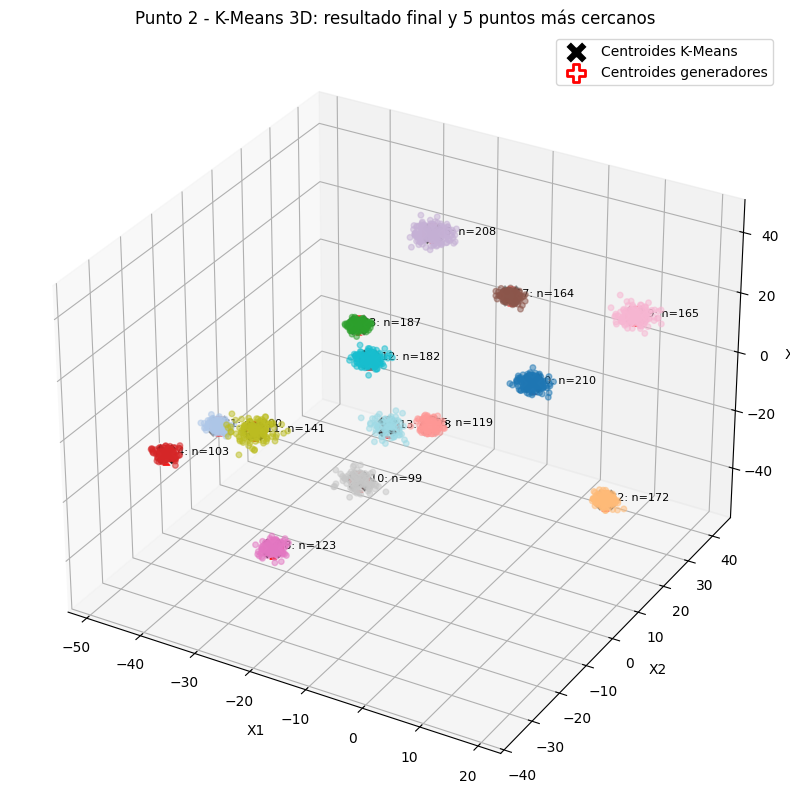

In [ ]:
# ============================================================
# GRÁFICA FINAL 3D
# ============================================================

fig = plt.figure(figsize=(13, 10))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    X3[:, 0], X3[:, 1], X3[:, 2],
    c=y3_pred, cmap="tab20", s=16, alpha=0.5
)
ax.scatter(
    centroides_3d_finales[:, 0], centroides_3d_finales[:, 1], centroides_3d_finales[:, 2],
    marker="X", s=260, c="black", edgecolors="white", linewidths=1.2,
    label="Centroides K-Means"
)
ax.scatter(
    centros_3d_generados[:, 0], centros_3d_generados[:, 1], centros_3d_generados[:, 2],
    marker="P", s=170, facecolors="none", edgecolors="red", linewidths=2,
    label="Centroides generadores"
)

for i, indices in indices_5_cercanos_3d.items():
    pts = X3[indices]
    ax.scatter(
        pts[:, 0], pts[:, 1], pts[:, 2],
        s=90, facecolors="none", edgecolors="black", linewidths=1.4
    )
    cx, cy, cz = centroides_3d_finales[i]
    ax.text(cx, cy, cz, f" C{i}: n={conteos_3d[i]}", fontsize=8)

ax.set_title("Punto 2 - K-Means 3D: resultado final y 5 puntos más cercanos")
ax.set_xlabel("X1")
ax.set_ylabel("X2")
ax.set_zlabel("X3")
ax.legend(loc="best")
plt.show()


### Visualización del proceso de entrenamiento en 3D

Se mantiene una inicialización común y se muestran varias etapas para observar cómo los centroides se desplazan hasta alcanzar la convergencia.

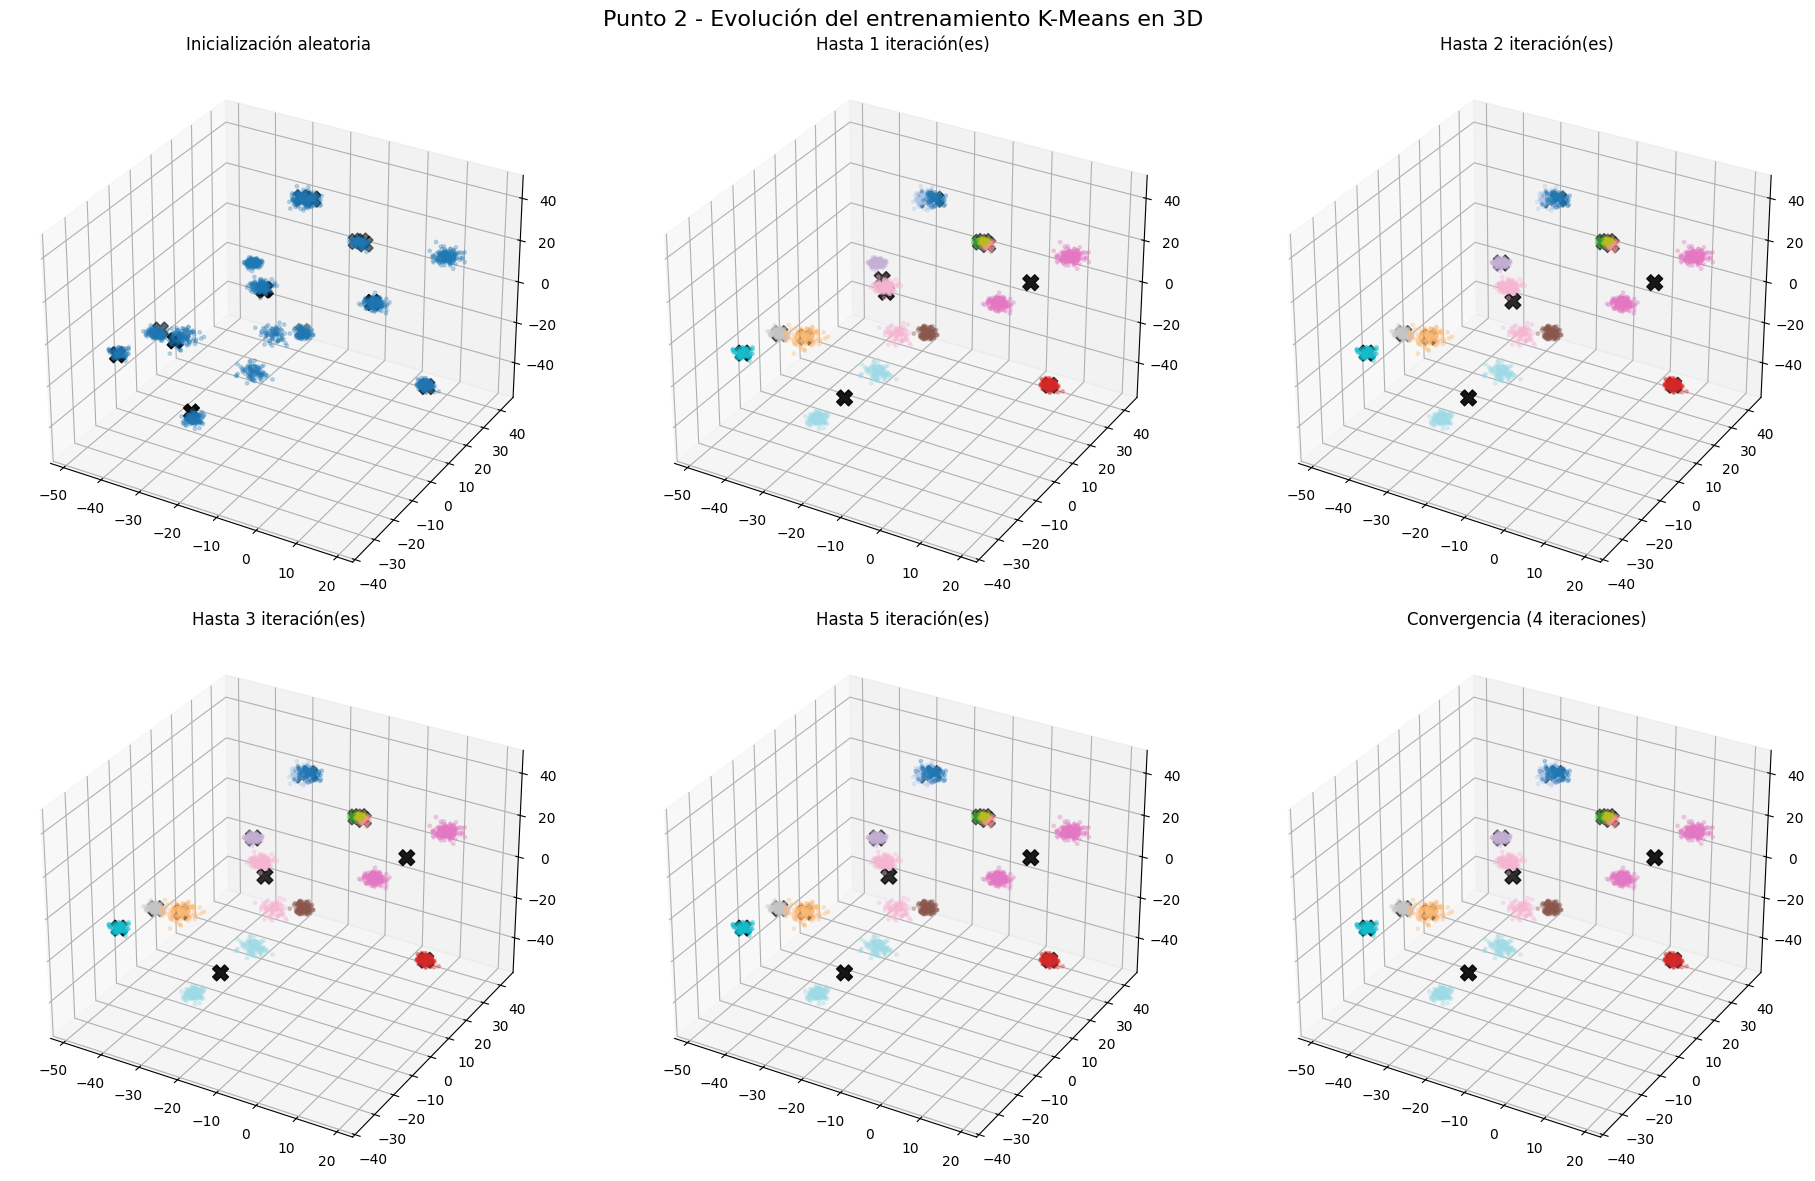

In [ ]:
# ============================================================
# PROCESO DE K-MEANS EN 3D
# ============================================================

rng_proceso3 = np.random.default_rng(123)
indices_init3 = rng_proceso3.choice(len(X3), size=k3, replace=False)
centros_init3 = X3[indices_init3].copy()

pasos3 = [1, 2, 3, 5]
modelos3 = []
for max_iter in pasos3:
    m = KMeans(
        n_clusters=k3,
        init=centros_init3,
        n_init=1,
        max_iter=max_iter,
        algorithm="lloyd",
        random_state=123
    ).fit(X3)
    modelos3.append((max_iter, m))

m3_final = KMeans(
    n_clusters=k3,
    init=centros_init3,
    n_init=1,
    max_iter=300,
    algorithm="lloyd",
    random_state=123
).fit(X3)

fig = plt.figure(figsize=(19, 12))

# Inicialización
ax = fig.add_subplot(2, 3, 1, projection="3d")
ax.scatter(X3[:, 0], X3[:, 1], X3[:, 2], s=6, alpha=0.25)
ax.scatter(centros_init3[:, 0], centros_init3[:, 1], centros_init3[:, 2], marker="X", s=130, c="black")
ax.set_title("Inicialización aleatoria")

# Iteraciones parciales
for pos, (max_iter, modelo) in enumerate(modelos3, start=2):
    ax = fig.add_subplot(2, 3, pos, projection="3d")
    ax.scatter(
        X3[:, 0], X3[:, 1], X3[:, 2],
        c=modelo.labels_, cmap="tab20", s=6, alpha=0.30
    )
    ax.scatter(
        modelo.cluster_centers_[:, 0], modelo.cluster_centers_[:, 1], modelo.cluster_centers_[:, 2],
        marker="X", s=130, c="black"
    )
    ax.set_title(f"Hasta {max_iter} iteración(es)")

# Convergencia
ax = fig.add_subplot(2, 3, 6, projection="3d")
ax.scatter(
    X3[:, 0], X3[:, 1], X3[:, 2],
    c=m3_final.labels_, cmap="tab20", s=6, alpha=0.30
)
ax.scatter(
    m3_final.cluster_centers_[:, 0], m3_final.cluster_centers_[:, 1], m3_final.cluster_centers_[:, 2],
    marker="X", s=130, c="black"
)
ax.set_title(f"Convergencia ({m3_final.n_iter_} iteraciones)")

plt.suptitle("Punto 2 - Evolución del entrenamiento K-Means en 3D", fontsize=16)
plt.tight_layout()
plt.show()


En lugar de asignar un grupo a cada muestra (*hard clustering*) se le puede asignar una puntuación (*soft clustering*) en función de su distancia al centroide.

In [ ]:
kmeans.transform(X_new)  # la  distancia de cada punto del X_neww

array([[43.06506145, 47.52555684, 58.87932858, 33.72511091, 52.60019339],
       [41.12710881, 46.15810641, 61.42676242, 32.18951169, 54.42569176],
       [44.41320312, 49.89117068, 55.81919357, 36.25145266, 50.05504258],
       [44.76490013, 49.4642054 , 56.09628284, 35.84877521, 50.46985265]])

Este algoritmo funciona asignando centroides de manera aleatoria y, de manera iterativa, asigna cada instancia a uno de ellos (el más cercano) tras lo cual se recalcula el centroide como el valor promedio de todas las instancias asignadas al grupo.

In [ ]:


# kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="full", max_iter=1, random_state=1)
# kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="lloyd", max_iter=1, random_state=1)
# kmeans_iter1 = KMeans(n_clusters=5, init="random", n_init=5,
#                      algorithm="elkan", max_iter=1, random_state=1)
# Configuración del modelo K-Means con inicialización inteligente
kmeans_iter1 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                      algorithm="elkan", max_iter=3, random_state=1)
# kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="full", max_iter=2, random_state=1)
# kmeans_iter2 = KMeans(n_clusters=5, init="random", n_init=5,
#                      algorithm="elkan", max_iter=2, random_state=1)
kmeans_iter2 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                     algorithm="elkan", max_iter=2, random_state=1)

# kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=1,
#                      algorithm="full", max_iter=3, random_state=1)
# kmeans_iter3 = KMeans(n_clusters=5, init="random", n_init=5,
#                      algorithm="elkan", max_iter=3, random_state=1)
kmeans_iter3 = KMeans(n_clusters=k, init="k-means++", n_init=1,
                     algorithm="elkan", max_iter=3, random_state=1)
kmeans_iter1.fit(X)
kmeans_iter2.fit(X)
kmeans_iter3.fit(X)

KMeans(algorithm='elkan', max_iter=3, n_clusters=5, n_init=1, random_state=1)

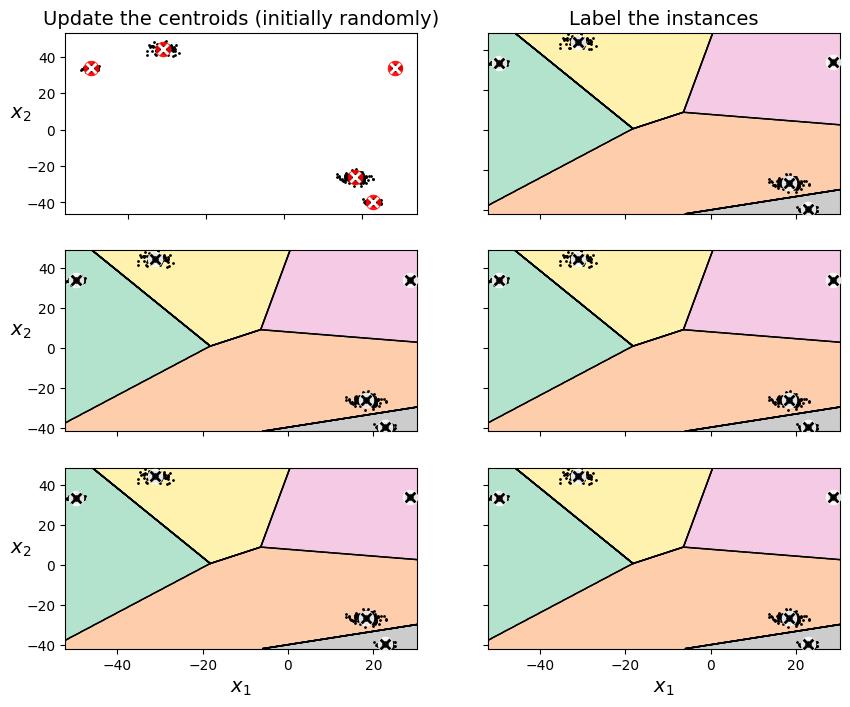

In [ ]:
plt.figure(figsize=(10, 8))

plt.subplot(321)
plot_data(X)
plot_centroids(kmeans_iter1.cluster_centers_, circle_color='r', cross_color='w')
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.tick_params(labelbottom=False)
plt.title("Update the centroids (initially randomly)", fontsize=14)

plt.subplot(322)
plot_decision_boundaries(kmeans_iter1, X, show_xlabels=False, show_ylabels=False)
plt.title("Label the instances", fontsize=14)

plt.subplot(323)
plot_decision_boundaries(kmeans_iter1, X, show_centroids=False, show_xlabels=False)
plot_centroids(kmeans_iter2.cluster_centers_)

plt.subplot(324)
plot_decision_boundaries(kmeans_iter2, X, show_xlabels=False, show_ylabels=False)

plt.subplot(325)
plot_decision_boundaries(kmeans_iter2, X, show_centroids=False)
plot_centroids(kmeans_iter3.cluster_centers_)

plt.subplot(326)
plot_decision_boundaries(kmeans_iter3, X, show_ylabels=False)

plt.show()

Esto implica que en función del estado inicial, el algoritmo puede llegar a una solución u otra.

In [ ]:
def plot_clusterer_comparison(clusterer1, clusterer2, X, title1=None, title2=None):
    clusterer1.fit(X)
    clusterer2.fit(X)

    plt.figure(figsize=(10, 3.2))

    plt.subplot(121)
    plot_decision_boundaries(clusterer1, X)
    if title1:
        plt.title(title1, fontsize=14)

    plt.subplot(122)
    plot_decision_boundaries(clusterer2, X, show_ylabels=False)
    if title2:
        plt.title(title2, fontsize=14)

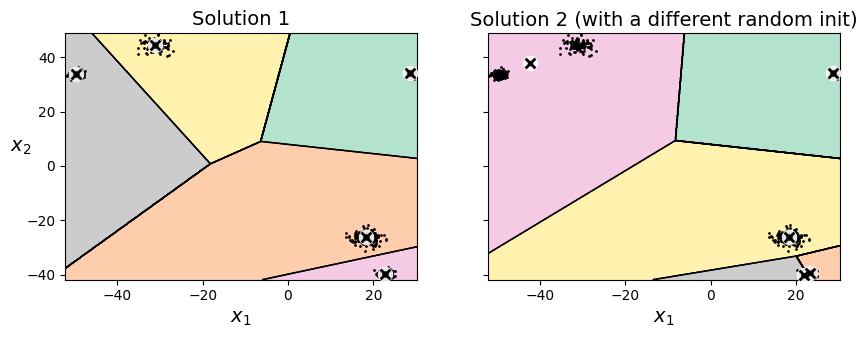

In [ ]:
kmeans_rnd_init1 = KMeans(n_clusters=k, init="random", n_init=1,
                         algorithm="elkan", random_state=11)
kmeans_rnd_init2 = KMeans(n_clusters=k, init="random", n_init=1,
                         algorithm="elkan", random_state=19)

plot_clusterer_comparison(kmeans_rnd_init1, kmeans_rnd_init2, X,"Solution 1", "Solution 2 (with a different random init)")

plt.show()

Para minimizar el impacto de la inicialización tenemos varias alternativas: probar varias y quedarnos con la mejor, o usar la inicialización inteligente que ofrece *Scikit-Learn* por defecto.

In [ ]:
kmeans_rnd_10_inits = KMeans(n_clusters=k, init="random", n_init=10,
                              algorithm="elkan", random_state=11)        # inicializando 10 y quedandome con el mejor resultado
kmeans_rnd_10_inits.fit(X)

KMeans(algorithm='elkan', init='random', n_clusters=5, n_init=10,
       random_state=11)

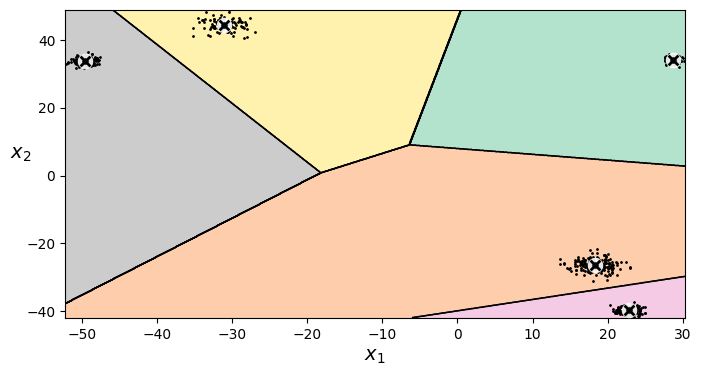

In [ ]:
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans_rnd_10_inits, X)
plt.show()

Otras mejoras al algoritmo de *K-Means* incluyen: *K-Means* acelerados (usado por *Scikit-Learn* por defecto y que evita algunos cálculos de distancias) y *mini-batch K-Means* (que puedes usarse si el dataset es tan grande que no cabe en memoria). Vamos a ver un ejemplo de este último caso con el dataset MNIST, para lo cual usaremos el objeto [MiniBatchKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.MiniBatchKMeans.html?highlight=minibatchkmeans#sklearn.cluster.MiniBatchKMeans).

In [ ]:
from sklearn.datasets import fetch_openml

mnist = fetch_openml('mnist_784', version=1)
mnist.target = mnist.target.astype(np.int64)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    mnist["data"], mnist["target"], random_state=42)

In [ ]:
def load_next_batch(batch_size):
    return X[np.random.choice(len(X), batch_size, replace=False)]

In [ ]:
from sklearn.cluster import MiniBatchKMeans

k = 5
n_init = 10
n_iterations = 100
batch_size = 100
init_size = 500
evaluate_on_last_n_iters = 10

best_kmeans = None # aqui creamosS variable para guardar el mejor modelo entrenado
# el entrenamiento de Mini-bacht kmeans
for init in range(n_init):
    minibatch_kmeans = MiniBatchKMeans(n_clusters=k, init_size=init_size)
    X_init = load_next_batch(init_size)
    minibatch_kmeans.partial_fit(X_init)

    minibatch_kmeans.sum_inertia_ = 0
    for iteration in range(n_iterations):
        X_batch = load_next_batch(batch_size)
        minibatch_kmeans.partial_fit(X_batch)
        if iteration >= n_iterations - evaluate_on_last_n_iters:
            minibatch_kmeans.sum_inertia_ += minibatch_kmeans.inertia_

    if (best_kmeans is None or
        minibatch_kmeans.sum_inertia_ < best_kmeans.sum_inertia_):
        best_kmeans = minibatch_kmeans

In [ ]:
best_kmeans.score(X)

-2196.09223582606

El algoritmo de *mini-batch K-Means* es más rápido que *K-Means* normal, pero su precisión suele ser peor.

### Encontrando el número óptimo de grupos

Como hemos visto anteriormente, el número de grupos o *clusters* es un hyperparámetro del modelo que debemos definir, y como podrás imaginar si nuestros datos no están etiquetados no será imposible saber qué valor usar. Para ello la solución se basa en usar diferentes valores y utilizar alguna métrica significativa. Una de estas métricas se conoce como el *silhouette score*, que se basa en calcular el coeficiente de silueta (*silhouette coefficient*) de todas las muestras del dataset como $(b-a)/\mathrm{max}(a,b)$ donde $a$ es la distancia mínima al resto de muestras del mismo grupo y $b$ es la distancia media de los grupos más cercanos. Su valor se encuentra entre $1$ y $-1$. Un valor cercano a $1$ indica que la muestra está bien metida en su grupo y lejos de los demás mientras que un valor cercano a $0$ indica que la muestra se encuentra cerca de una frontera de decisión y un valor cercano a $-1$ indica que la muestra está en el grupo incorrecto.

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

np.float64(0.8799010075310776)

Calculando la métrica para diferentes números de *clusters* podemos encontrar el valor óptimo.

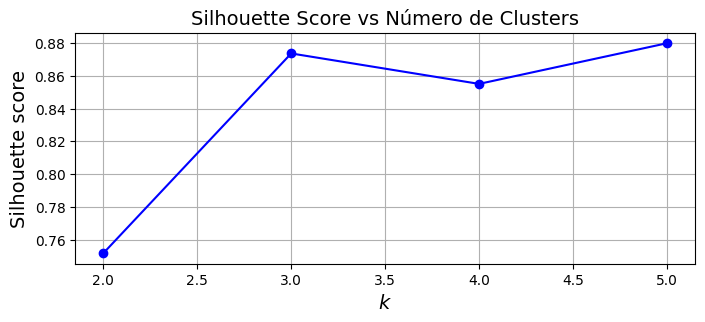

In [ ]:
#kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, 10)]
#silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

#max_k = min(20, len(blob_centers))  # no más de los centros generados
#kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]
#silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

#plt.figure(figsize=(8, 3))
#plt.plot(range(2, 10), silhouette_scores, "bo-")
#plt.xlabel("$k$", fontsize=14)
#plt.ylabel("Silhouette score", fontsize=14)
#plt.axis([1.8, 8.5, 0.55, 0.7])
#plt.show()

import matplotlib.pyplot as plt

# Definir máximo valor de k
max_k = min(20, len(blob_centers))

# Entrenar un modelo KMeans para cada k de 1 hasta max_k
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X) for k in range(1, max_k + 1)]

# Calcular silhouette_scores para k ≥ 2
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]]

# Generar eje x para k de 2 hasta max_k
ks = list(range(2, max_k + 1))

# Graficar
plt.figure(figsize=(8, 3))
plt.plot(ks, silhouette_scores, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Silhouette score", fontsize=14)
plt.title("Silhouette Score vs Número de Clusters", fontsize=14)
plt.grid(True)
plt.show()


También es muy útil visualizar los diagramas de silueta, en el que visualizaremos todos los coeficientes de silueta ordenados por grupos y su valor.

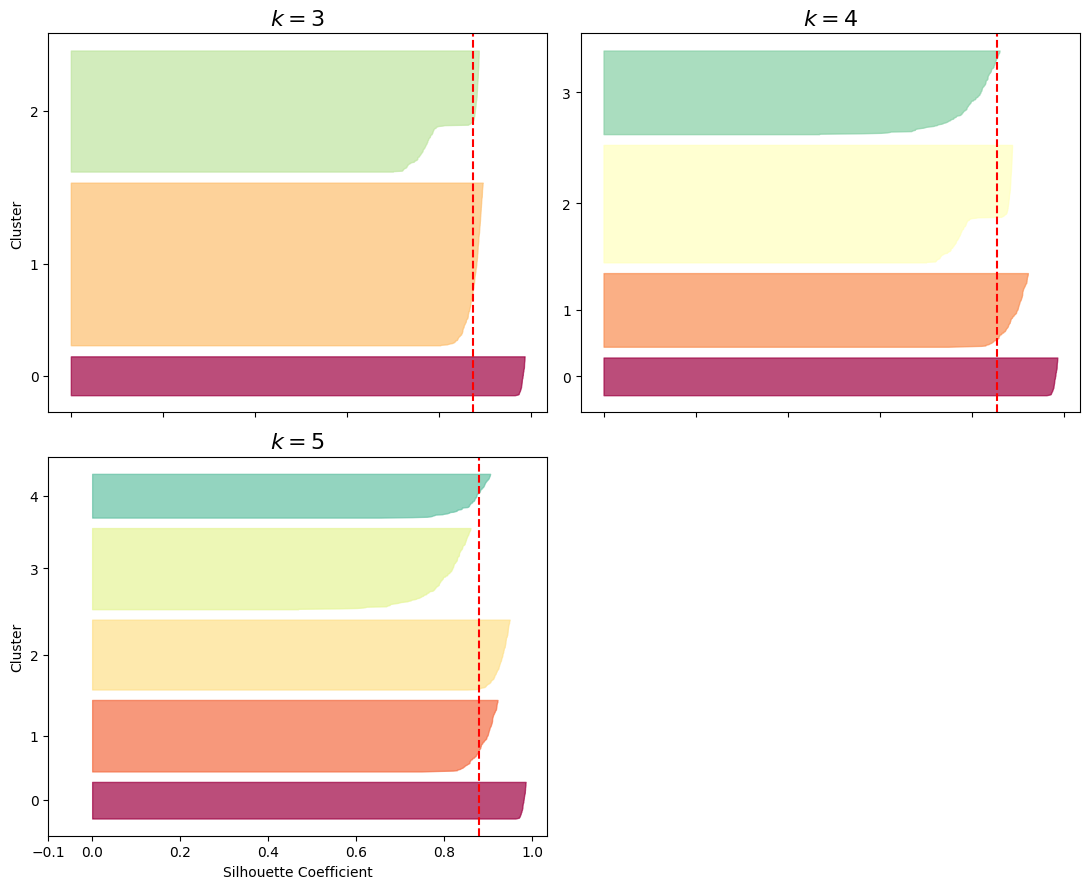

In [ ]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

plt.figure(figsize=(11, 9))

valid_ks = [k for k in (3, 4, 5, 6) if k <= len(kmeans_per_k)]  # Filtrar solo los ks válidos


for plot_idx, k in enumerate(valid_ks):
    plt.subplot(2, 2, plot_idx + 1)  # enumerar para evitar errores

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    if k - 2 < len(silhouette_scores):
        plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$", fontsize=16)

plt.tight_layout()
plt.show()


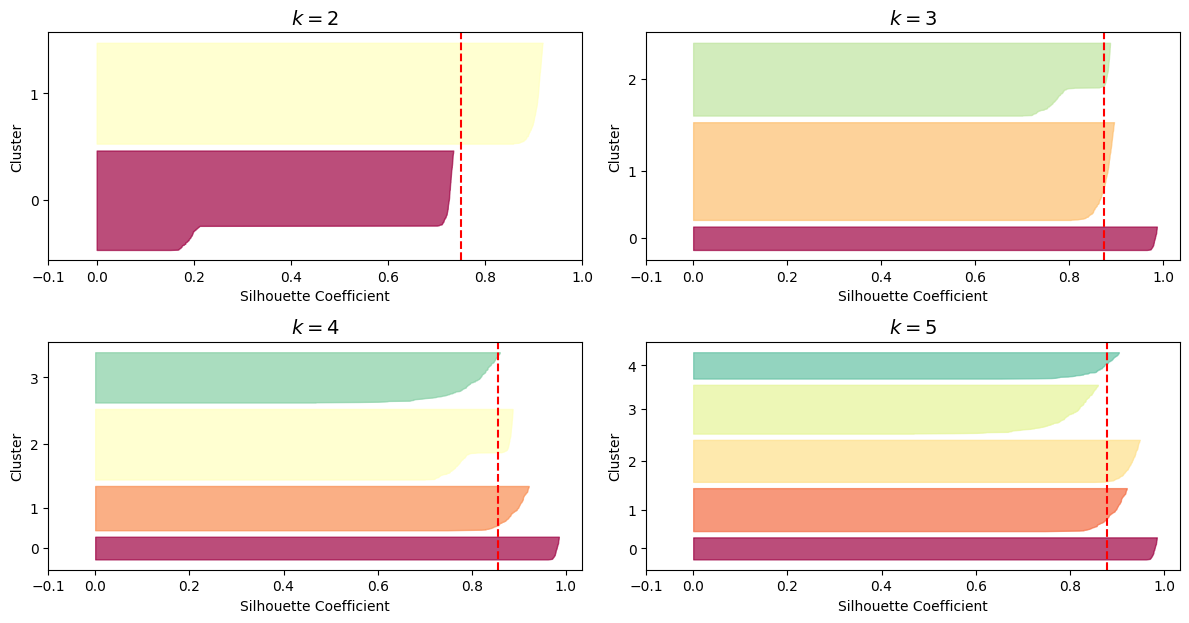

In [ ]:
from sklearn.metrics import silhouette_samples
from matplotlib.ticker import FixedLocator, FixedFormatter
import matplotlib as mpl

n_ks = len(kmeans_per_k)  # Total de modelos entrenados
plt.figure(figsize=(12, 3 * ((n_ks - 1) // 2 + 1)))  # ajustar el alto automáticamente

for plot_idx, k in enumerate(range(2, n_ks + 1)):  # desde k=2 hasta máximo
    plt.subplot((n_ks - 1) // 2 + 1, 2, plot_idx + 1)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = mpl.cm.Spectral(i / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    plt.ylabel("Cluster")

    plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
    plt.xlabel("Silhouette Coefficient")

    if k - 2 < len(silhouette_scores):
        plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$", fontsize=14)

plt.tight_layout()
plt.show()


### K-Means para aprendizaje semi-supervisado.

El aprendizaje semi-supervisado (o *Semi-supervised Learning*) comprende el conjunto de técnicas que nos permiten entrenar modelos con datasets parcialmente etiquetados. En esta sección vamos a ver un ejemplo de como podemos aplicar esta técnica con el dataset MNIST y usando *K-Means*. Empezamos descargando el dataset.

In [ ]:
from sklearn.datasets import fetch_lfw_people


# Cargar el dataset con imágenes de al menos 70 rostros por persona (puedes ajustar min_faces_per_person)
lfw_dataset = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

# Acceder a los datos
X = lfw_dataset.data          # Imágenes en formato vectorizado (flattened)
y = lfw_dataset.target        # Etiquetas (persona)
target_names = lfw_dataset.target_names  # Nombres de las personas

# Verificar las dimensiones
print("Shape de X:", X.shape)
print("Número de clases:", len(target_names))


Shape de X: (1288, 1850)
Número de clases: 7


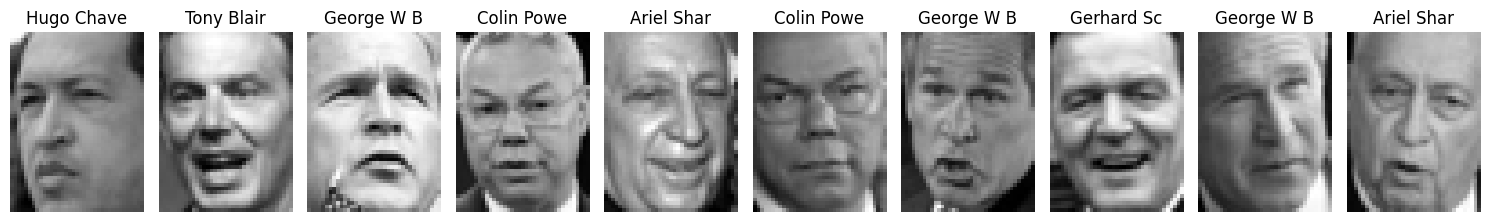

In [ ]:
import matplotlib.pyplot as plt

# Mostrar las primeras 10 imágenes del dataset
fig, axes = plt.subplots(1, 10, figsize=(15, 8))
for i in range(10):
    axes[i].imshow(lfw_dataset.images[i], cmap="gray")
    axes[i].axis("off")
    axes[i].set_title(target_names[y[i]][:10])  # mostrar el nombre
plt.tight_layout()
plt.show()


In [ ]:
#preparar el dataset
from sklearn.model_selection import train_test_split
import numpy as np

# Cargamos el dataset
lfw = fetch_lfw_people(min_faces_per_person=70, resize=0.4)

X = lfw.data  # características (imagenes aplanadas)
y = lfw.target  # etiquetas (personas)
target_names = lfw.target_names  # nombres de personas

print("Shape de X:", X.shape)  # ejemplo: (1288, 1850)
print("Cantidad de clases:", len(target_names))

# Dividimos en conjunto de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)


Shape de X: (1288, 1850)
Cantidad de clases: 7


In [ ]:
from sklearn.cluster import KMeans

k = 50  # número de clusters
kmeans = KMeans(n_clusters=k, random_state=42)
X_faces_dist = kmeans.fit_transform(X_train)  # distancia a cada centroide

print("Shape de distancias:", X_faces_dist.shape)


Shape de distancias: (966, 50)


In [ ]:
idxs = np.argmin(X_faces_dist, axis=0)  # índice más cercano a cada centroide
X_representative_faces = X_train[idxs]  # imágenes representativas

print("Shape:", X_representative_faces.shape)


Shape: (50, 1850)


In [1]:
print(idxs)

NameError: name 'idxs' is not defined

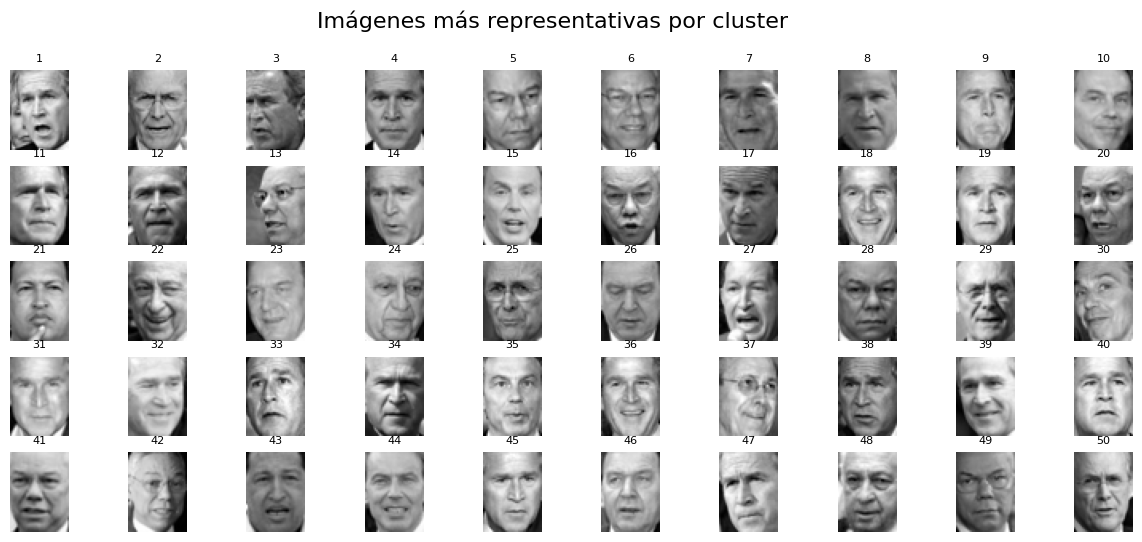

In [ ]:
import matplotlib.pyplot as plt

h, w = lfw.images.shape[1:3]  # alto y ancho original

plt.figure(figsize=(15, 6))
for index, face in enumerate(X_representative_faces):
    plt.subplot(5, 10, index + 1)
    plt.imshow(face.reshape(h, w), cmap="gray")
    plt.title(f"{index+1}", fontsize=8)
    plt.axis('off')
plt.suptitle("Imágenes más representativas por cluster", fontsize=16)
plt.show()


In [ ]:
# Obtener las etiquetas reales de las imágenes más representativas
y_representative_faces = y_train[idxs]


In [ ]:
from sklearn.linear_model import LogisticRegression

log_reg2 = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg2.fit(X_representative_faces, y_representative_faces)

# Evaluamos el modelo en el conjunto de prueba
print("Precisión usando solo imágenes representativas:", log_reg2.score(X_test, y_test))




/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


CPU times: user 619 ms, sys: 5.23 ms, total: 625 ms
Wall time: 335 ms
Precisión usando solo imágenes representativas: 0.5341614906832298


In [ ]:
log_reg_random = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg_random.fit(X_train[:50], y_train[:50])

# Evaluamos el modelo en el conjunto de prueba
print("Precisión usando 50 imágenes aleatorias:", log_reg_random.score(X_test, y_test))



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


CPU times: user 729 ms, sys: 5.65 ms, total: 734 ms
Wall time: 397 ms
Precisión usando 50 imágenes aleatorias: 0.4813664596273292


In [ ]:
# Propagación de etiquetas representativas a todo el conjunto de entrenamiento
y_train_propagated = np.empty(len(X_train))
for i in range(k):
    y_train_propagated[kmeans.labels_ == i] = y_representative_faces[i]

# Entrenamiento con las etiquetas propagadas
log_reg3 = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)
%time log_reg3.fit(X_train[:1000], y_train_propagated[:1000])

print("Precisión con 1000 muestras semi-etiquetadas:", log_reg3.score(X_test, y_test))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


CPU times: user 19.1 s, sys: 24 ms, total: 19.1 s
Wall time: 11.2 s
Precisión con 1000 muestras semi-etiquetadas: 0.391304347826087


## Aprendizaje Activo

In [ ]:
# Calculamos las probabilidades de las primeras 1000 muestras
probas = log_reg3.predict_proba(X_train[:1000])

# Obtenemos el índice de la clase más probable para cada muestra
labels_ixs = np.argmax(probas, axis=1)

# Obtenemos la confianza (probabilidad máxima) de cada predicción
confidences = probas[np.arange(len(probas)), labels_ixs]



In [ ]:
# Ordenamos por confianza (de menor a mayor)
sorted_ixs = np.argsort(confidences)

k = 50  # cantidad de muestras "inciertas" a revisar

# Obtenemos las 50 imágenes más inciertas
X_lowest = X_train[:1000][sorted_ixs[:k]]
y_lowest = y_train[:1000][sorted_ixs[:k]]


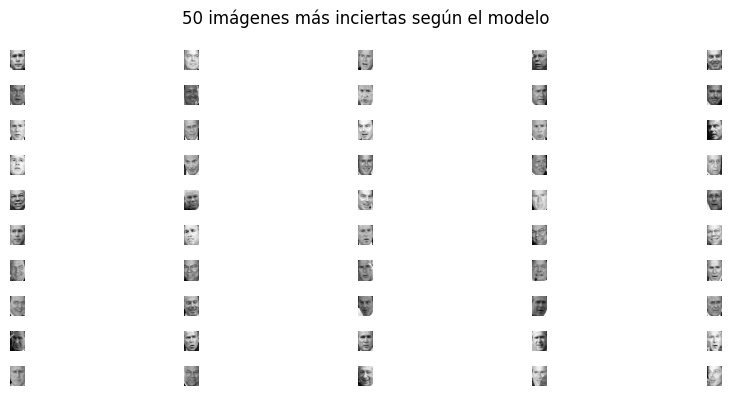

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
for i in range(10):
    for j in range(5):
        idx = i * 5 + j
        image = X_lowest[idx].reshape(50, 37)
        plt.subplot(10, 5, idx + 1)
        plt.imshow(image, cmap="gray")
        plt.axis("off")
plt.suptitle("50 imágenes más inciertas según el modelo")
plt.tight_layout()
plt.show()


In [ ]:
log_reg_active = LogisticRegression(multi_class="ovr", solver="lbfgs", max_iter=5000, random_state=42)

# Entrenamos con las 50 muestras inciertas (suponemos que ya están etiquetadas correctamente)
%time log_reg_active.fit(X_lowest, y_lowest)

# Evaluamos en el conjunto de prueba
print("Precisión usando aprendizaje activo (50 imágenes inciertas):", log_reg_active.score(X_test, y_test))


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


CPU times: user 502 ms, sys: 5.79 ms, total: 507 ms
Wall time: 287 ms
Precisión usando aprendizaje activo (50 imágenes inciertas): 0.5341614906832298
